# Análisis vectorial y ráster de Colombia con GeoPandas

**Parte 1 – Biblioteca principal: GeoPandas** (con apoyo de Shapely y Rasterio)

## 1. Problema geográfico
¿Cómo se distribuye la población urbana entre los departamentos de Colombia y cómo se relaciona con el relieve y la red hídrica?
Se buscan los departamentos con **mayor densidad de población urbana** (suma de la población de sus ciudades por km²) y se contrasta con su relieve y con la longitud de ríos que los atraviesan.

## 2. Procedencia de los datos
Todos los datos provienen de [Natural Earth](https://www.naturalearthdata.com/downloads/) (dominio público, sin restricciones de uso):

| Capa | Tipo | Escala | Uso |
|---|---|---|---|
| `ne_10m_admin_1_states_provinces` | Vector (polígonos) | 1:10m | Departamentos |
| `ne_10m_populated_places` | Vector (puntos) | 1:10m | Ciudades y población |
| `ne_10m_rivers_lake_centerlines` | Vector (líneas) | 1:10m | Ríos |
| `SR_50M` | Ráster (1 banda, relieve sombreado en grises) | 1:50m | Relieve |
| `ne_10m_geography_regions_elevation_points` | Vector (puntos) | 1:10m | Picos con elevación (m) |

> **Limitación:** `SR_50M` es un relieve sombreado, no un modelo de elevación (DEM). Sus valores sirven como *indicador* de relieve, no como metros sobre el nivel del mar.

## 3. Preparación del entorno

In [1]:
import importlib.util
import subprocess
import urllib.request
import warnings
import zipfile
from pathlib import Path

# Colab incluye geopandas y shapely; rasterio se instala solo si falta
if importlib.util.find_spec("rasterio") is None:
    subprocess.run(["uv", "pip", "install", "--system", "-q", "rasterio"], check=True)

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pyproj
import rasterio
import shapely
from rasterio import features
from rasterio.mask import mask
from rasterio.plot import plotting_extent
from rasterio.transform import rowcol
from scipy.ndimage import generic_filter
from shapely.geometry import MultiPoint, Point, Polygon, shape
from shapely.ops import nearest_points

CRS_METRICO = "EPSG:9377"  # MAGNA-SIRGAS Origen Nacional (metros)

**Funciones de cartografía.** Título, flecha de norte y barra de escala para todos los mapas, y exportación de cada figura a `outputs/` para el informe.

In [2]:
SALIDAS = Path("outputs")
SALIDAS.mkdir(exist_ok=True)

def decorar_mapa(ax, titulo, km=None, grados=False, norte=True):
    """Título, flecha de norte y barra de escala de `km` km (aproximada si el mapa está en grados)."""
    ax.set_title(titulo)
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    if norte:
        ax.annotate("N", xy=(0.94, 0.96), xytext=(0.94, 0.86), xycoords="axes fraction", ha="center",
                    fontsize=11, fontweight="bold", arrowprops={"arrowstyle": "-|>", "color": "black"})
    if km:
        largo = km * 1000
        if grados:  # 1° de longitud ≈ 111,32 km · cos(latitud)
            largo = km / (111.32 * np.cos(np.radians((y0 + y1) / 2)))
        x, y = x0 + 0.05 * (x1 - x0), y0 + 0.04 * (y1 - y0)
        ax.plot([x, x + largo], [y, y], color="black", linewidth=3, solid_capstyle="butt")
        ax.text(x + largo / 2, y + 0.012 * (y1 - y0), f"{km} km", ha="center", fontsize=8)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)

def guardar(fig, nombre):
    """Exporta la figura a outputs/."""
    fig.savefig(SALIDAS / f"{nombre}.png", dpi=200, bbox_inches="tight")

## 4. Descarga de datos

In [3]:
BASE = "https://naciscdn.org/naturalearth"
DATOS = Path("data")

def descargar(ruta):
    """Descarga y descomprime un recurso de Natural Earth (si no existe ya)."""
    nombre = Path(ruta).stem
    destino = DATOS / nombre
    if not destino.exists():
        DATOS.mkdir(exist_ok=True)
        zip_local = DATOS / f"{nombre}.zip"
        urllib.request.urlretrieve(f"{BASE}/{ruta}", zip_local)
        with zipfile.ZipFile(zip_local) as z:
            z.extractall(destino)
        zip_local.unlink()
    return destino

d_deptos = descargar("10m/cultural/ne_10m_admin_1_states_provinces.zip")
d_ciudades = descargar("10m/cultural/ne_10m_populated_places.zip")
d_rios = descargar("10m/physical/ne_10m_rivers_lake_centerlines.zip")
d_relieve = descargar("50m/raster/SR_50M.zip")
d_picos = descargar("10m/physical/ne_10m_geography_regions_elevation_points.zip")

## 5. Datos vectoriales: lectura y consulta de atributos
**Operación 1 – Lectura y filtrado.** Se leen los shapefiles y se filtran las entidades de Colombia por código de país.

In [4]:
# Se descarta una isla menor sin nombre (Malpelo, 8 km²) que no es un departamento: quedan 32 + Bogotá D.C.
deptos = gpd.read_file(d_deptos).query("adm0_a3 == 'COL'").dropna(subset=["name"])[["name", "type", "geometry"]]
deptos = deptos.rename(columns={"name": "departamento"}).reset_index(drop=True)

ciudades = gpd.read_file(d_ciudades).query("ADM0_A3 == 'COL'")[["NAME", "POP_MAX", "FEATURECLA", "geometry"]]
ciudades = ciudades.rename(columns={"NAME": "ciudad", "POP_MAX": "poblacion"}).reset_index(drop=True)

rios = gpd.read_file(d_rios)[["name", "geometry"]]

print(f"{len(deptos)} departamentos | {len(ciudades)} ciudades | {len(rios)} tramos de ríos (mundo)")
print("CRS original:", deptos.crs)
deptos.head()

33 departamentos | 72 ciudades | 1473 tramos de ríos (mundo)
CRS original: EPSG:4326


,departamento,type,geometry
0,Nariño,Departamento,"MULTIPOLYGON (((-78.64127 1.25941, -78.66468 1..."
1,Putumayo,Intendencia,"POLYGON ((-76.17759 0.40013, -76.20209 0.40179..."
2,Chocó,Departamento,"MULTIPOLYGON (((-77.46937 8.53781, -77.44113 8..."
3,Guainía,Comisaría,"POLYGON ((-67.06523 1.17269, -67.08611 1.176, ..."
4,Vaupés,Comisaría,"POLYGON ((-69.84118 1.70758, -69.85617 1.70767..."


In [5]:
# Consulta por atributos: las 5 ciudades más pobladas
ciudades.nlargest(5, "poblacion")[["ciudad", "poblacion"]]

,ciudad,poblacion
71,Bogota,7772000
69,Medellín,3297000
70,Cali,2254000
65,Barranquilla,1798000
56,Bucaramanga,1009000


## 6. Reproyección y cálculo de áreas
**Operación 2 – Reproyección y áreas.** Los datos vienen en grados (EPSG:4326), que no sirven para medir áreas ni distancias. Se reproyectan a EPSG:9377 (metros) antes de calcular.

In [6]:
deptos = deptos.to_crs(CRS_METRICO)
ciudades = ciudades.to_crs(CRS_METRICO)

deptos["area_km2"] = deptos.area / 1e6
print(f"Área total: {deptos.area_km2.sum():,.0f} km² (referencia oficial ≈ 1.141.748 km²)")
deptos.sort_values("area_km2", ascending=False)[["departamento", "type", "area_km2"]].head(8).round(0)

Área total: 1,135,637 km² (referencia oficial ≈ 1.141.748 km²)


,departamento,type,area_km2
5,Amazonas,Comisaría,109206.0
11,Vichada,Comisaría,98874.0
21,Caquetá,Intendencia,89972.0
26,Meta,Departamento,86109.0
3,Guainía,Comisaría,71594.0
14,Antioquia,Departamento,63388.0
23,Guaviare,Comisaría,54975.0
4,Vaupés,Comisaría,51766.0


**Justificación del CRS.** Se compara el área en grados² (EPSG:4326), en km² con EPSG:9377 y la área geodésica sobre el elipsoide WGS84 (referencia más exacta).
Los grados² no son una unidad de superficie; EPSG:9377 es una proyección diseñada para Colombia y debería acercarse a la geodésica.

In [7]:
geod = pyproj.Geod(ellps="WGS84")
geo = deptos.to_crs("EPSG:4326").geometry
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # aviso esperado: área en CRS geográfico
    grados2 = geo.area

comp = deptos[["departamento"]].assign(
    grados2=grados2,
    km2_9377=deptos.area_km2,
    km2_geodesica=geo.apply(lambda g: abs(geod.geometry_area_perimeter(g)[0])) / 1e6,
)
comp["error_%"] = (comp.km2_9377 / comp.km2_geodesica - 1) * 100
print(f"Error medio absoluto de EPSG:9377 vs geodésica: {comp['error_%'].abs().mean():.2f} %")
print(f"Error máximo: {comp['error_%'].abs().max():.2f} % ({comp.loc[comp['error_%'].abs().idxmax(), 'departamento']})")
comp.sort_values("km2_geodesica", ascending=False).head(5).round(3)

Error medio absoluto de EPSG:9377 vs geodésica: 0.19 %
Error máximo: 2.00 % (San Andrés y Providencia)


,departamento,grados2,km2_9377,km2_geodesica,error_%
5,Amazonas,8.880,109205.544,109254.313,-0.045
11,Vichada,8.039,98874.219,98613.782,0.264
21,Caquetá,7.318,89971.999,90055.561,-0.093
26,Meta,7.017,86108.736,86220.336,-0.129
3,Guainía,5.800,71594.022,71308.177,0.401


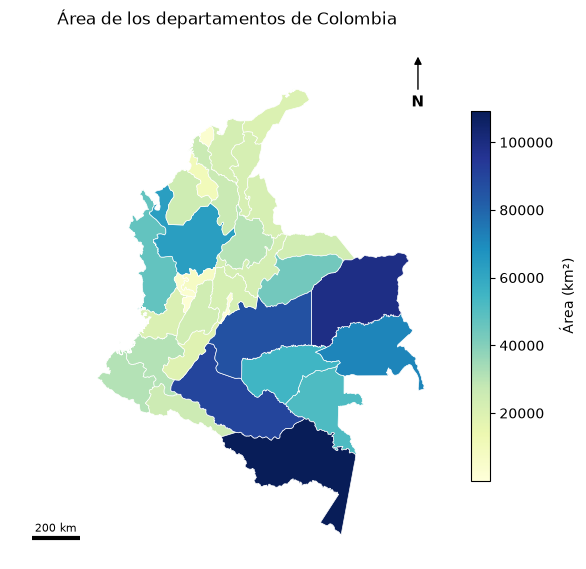

In [8]:
fig, ax = plt.subplots(figsize=(7, 8))
deptos.plot(column="area_km2", cmap="YlGnBu", legend=True, edgecolor="white", linewidth=0.5, ax=ax,
            legend_kwds={"label": "Área (km²)", "shrink": 0.6})
decorar_mapa(ax, "Área de los departamentos de Colombia", km=200)
ax.set_axis_off()
guardar(fig, "01_area_departamentos")
plt.show()

## 7. Combinación de capas
**Operación 3 – Unión espacial (`sjoin`).** Se asigna cada ciudad a su departamento y se agrega población y número de ciudades.

**Operación 4 – Recorte e intersección de líneas con polígonos (`clip` / `overlay`).** Se recortan los ríos a Colombia y se mide cuántos km de río hay en cada departamento.

In [9]:
# Ciudades -> departamento
ciu_dep = gpd.sjoin(ciudades, deptos[["departamento", "geometry"]], how="left", predicate="within")
ciu_dep = ciu_dep[~ciu_dep.index.duplicated()].drop(columns="index_right")

# Los polígonos generalizados (1:10m) pueden dejar fuera ciudades costeras o insulares:
# se asignan al departamento más cercano
sin_dep = ciu_dep.departamento.isna()
if sin_dep.any():
    cerca = gpd.sjoin_nearest(ciudades[sin_dep], deptos[["departamento", "geometry"]], distance_col="dist_m")
    cerca = cerca[~cerca.index.duplicated()]
    ciu_dep.loc[sin_dep, "departamento"] = cerca.departamento
    print("Ciudades asignadas por cercanía:")
    print(cerca[["ciudad", "departamento", "dist_m"]].round(0).to_string())

resumen = (ciu_dep.groupby("departamento")
           .agg(n_ciudades=("ciudad", "count"), pob_urbana=("poblacion", "sum"))
           .reset_index())
deptos = deptos.drop(columns=["n_ciudades", "pob_urbana"], errors="ignore").merge(resumen, on="departamento", how="left")
deptos[["n_ciudades", "pob_urbana"]] = deptos[["n_ciudades", "pob_urbana"]].fillna(0)
deptos["densidad_urbana"] = deptos.pob_urbana / deptos.area_km2

Ciudades asignadas por cercanía:
       ciudad              departamento  dist_m
1  San Andrés  San Andrés y Providencia    44.0


In [10]:
# Ríos recortados al territorio colombiano (se recorta antes de reproyectar: los ríos
# de otras latitudes no se proyectan bien a un CRS local) y longitud por departamento
rios_col = gpd.clip(rios, deptos.to_crs(rios.crs).union_all()).to_crs(CRS_METRICO)
rios_dep = gpd.overlay(rios_col, deptos[["departamento", "geometry"]], how="intersection")
rios_dep["km"] = rios_dep.length / 1000

deptos = deptos.merge(rios_dep.groupby("departamento").km.sum().rename("km_rios"), on="departamento", how="left")
deptos["km_rios"] = deptos.km_rios.fillna(0)
deptos.sort_values("km_rios", ascending=False)[["departamento", "km_rios"]].head(5).round(0)

,departamento,km_rios
5,Amazonas,1356.0
26,Meta,774.0
11,Vichada,771.0
3,Guainía,767.0
14,Antioquia,636.0


## 8. Reto: departamentos con mayor densidad urbana
Se seleccionan los departamentos que cumplen **ambas** condiciones: densidad urbana en el cuartil superior (percentil 75) y al menos 1 millón de habitantes urbanos.
El segundo filtro descarta departamentos pequeños con una población urbana poco relevante en términos absolutos.

In [11]:
umbral = deptos.densidad_urbana.quantile(0.75)
deptos["reto"] = (deptos.densidad_urbana >= umbral) & (deptos.pob_urbana >= 1_000_000)
reto = deptos[deptos.reto]

print(f"Umbral de densidad urbana (P75): {umbral:.1f} hab/km²")
reto.sort_values("densidad_urbana", ascending=False)[
    ["departamento", "n_ciudades", "pob_urbana", "area_km2", "densidad_urbana", "km_rios"]].round(1)

Umbral de densidad urbana (P75): 41.6 hab/km²


,departamento,n_ciudades,pob_urbana,area_km2,densidad_urbana,km_rios
27,Bogota,1.0,7772000.0,1668.1,4659.3,0.7
18,Atlántico,3.0,2565387.0,3341.2,767.8,103.1
13,Valle del Cauca,4.0,2807133.0,20922.9,134.2,231.4
14,Antioquia,6.0,3955293.0,63388.2,62.4,636.2
17,Bolívar,4.0,1098698.0,26441.1,41.6,587.2


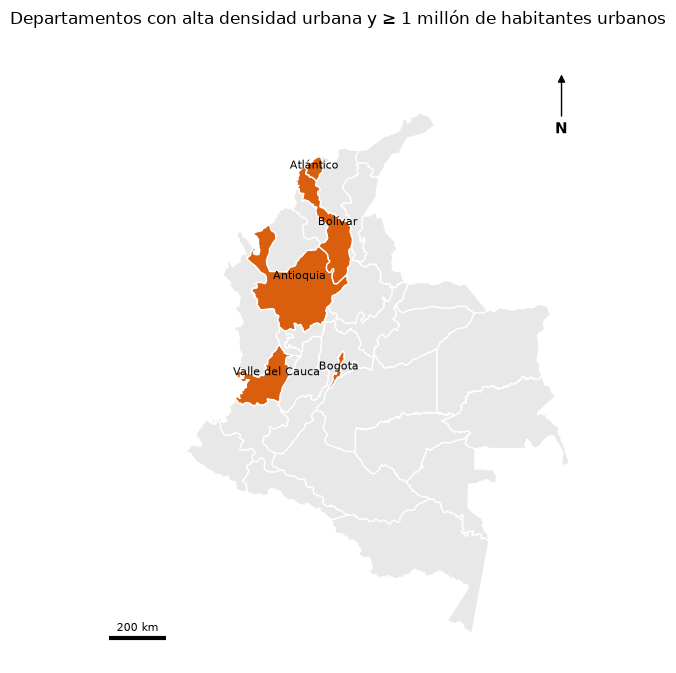

In [12]:
fig, ax = plt.subplots(figsize=(7, 8))
deptos.plot(color="#e8e8e8", edgecolor="white", ax=ax)
reto.plot(color="#d95f0e", edgecolor="white", ax=ax)
for _, r in reto.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r.departamento, (p.x, p.y), ha="center", fontsize=8)
decorar_mapa(ax, "Departamentos con alta densidad urbana y ≥ 1 millón de habitantes urbanos", km=200)
ax.set_axis_off()
guardar(fig, "02_reto_densidad_urbana")
plt.show()

**Sensibilidad del umbral.** Se repite el reto con otros percentiles para comprobar que la selección no depende de un valor arbitrario.

In [13]:
for p in (0.60, 0.75, 0.90):
    u = deptos.densidad_urbana.quantile(p)
    sel = deptos[(deptos.densidad_urbana >= u) & (deptos.pob_urbana >= 1_000_000)]
    nombres = ", ".join(sel.sort_values("densidad_urbana", ascending=False).departamento)
    print(f"P{int(p * 100)} (≥ {u:.1f} hab/km²): {nombres}")

P60 (≥ 23.4 hab/km²): Bogota, Atlántico, Valle del Cauca, Antioquia, Bolívar, Santander
P75 (≥ 41.6 hab/km²): Bogota, Atlántico, Valle del Cauca, Antioquia, Bolívar
P90 (≥ 165.8 hab/km²): Bogota, Atlántico


## 9. Distribución espacial de la población
¿Dónde está el "centro" de la población urbana y cuánto depende el país de unas pocas ciudades? Se calcula el centro medio ponderado, la primacía urbana, la distancia de cada ciudad a un río y las zonas de influencia (polígonos de Voronoi) de las ciudades grandes.

In [14]:
# Centro medio ponderado por población vs centroide geográfico del país
pob = ciudades.poblacion
centro_pob = Point((ciudades.geometry.x * pob).sum() / pob.sum(), (ciudades.geometry.y * pob).sum() / pob.sum())
centro_geo = deptos.union_all().centroid

ll = gpd.GeoSeries([centro_pob, centro_geo], crs=CRS_METRICO).to_crs("EPSG:4326")
print(f"Centro de población: lon {ll[0].x:.2f}, lat {ll[0].y:.2f} | Centroide geográfico: lon {ll[1].x:.2f}, lat {ll[1].y:.2f}")
print(f"Distancia entre ambos: {centro_pob.distance(centro_geo) / 1000:.0f} km")

# Primacía urbana: peso de las ciudades más grandes sobre la población urbana registrada
orden = ciudades.poblacion.sort_values(ascending=False)
for k in (1, 3, 5):
    print(f"Top {k}: {orden.head(k).sum() / orden.sum() * 100:.1f} % de la población urbana registrada")

Centro de población: lon -74.83, lat 6.05 | Centroide geográfico: lon -73.08, lat 3.90
Distancia entre ambos: 307 km
Top 1: 29.2 % de la población urbana registrada
Top 3: 50.1 % de la población urbana registrada
Top 5: 60.7 % de la población urbana registrada


In [15]:
# Distancia de cada ciudad al río más cercano (la capa solo incluye los ríos principales)
cerca = gpd.sjoin_nearest(ciudades, rios_col[["geometry"]], distance_col="dist_rio_m")
ciudades["dist_rio_km"] = cerca[~cerca.index.duplicated()].dist_rio_m / 1000

dentro = ciudades.dist_rio_km <= 25
print(f"Población en ciudades a ≤ 25 km de un río principal: {ciudades.poblacion[dentro].sum() / pob.sum() * 100:.1f} % ({dentro.sum()} de {len(ciudades)} ciudades)")
ciudades.nlargest(5, "poblacion")[["ciudad", "poblacion", "dist_rio_km"]].round(1)

Población en ciudades a ≤ 25 km de un río principal: 59.8 % (34 de 72 ciudades)


,ciudad,poblacion,dist_rio_km
71,Bogota,7772000,18.3
69,Medellín,3297000,30.2
70,Cali,2254000,5.9
65,Barranquilla,1798000,4.5
56,Bucaramanga,1009000,84.8


In [16]:
# Zonas de influencia: Voronoi de las ciudades >= 300.000 hab. recortado al territorio
grandes = ciudades[ciudades.poblacion >= 300_000]
contorno = deptos.union_all()
celdas = gpd.GeoDataFrame(
    geometry=list(shapely.voronoi_polygons(MultiPoint(grandes.geometry.tolist()), extend_to=contorno.envelope).geoms),
    crs=CRS_METRICO,
)
celdas["geometry"] = celdas.intersection(contorno)
voronoi = gpd.sjoin(celdas, grandes[["ciudad", "poblacion", "geometry"]], predicate="contains").drop(columns="index_right")
voronoi["area_km2"] = voronoi.area / 1e6
voronoi.sort_values("area_km2", ascending=False)[["ciudad", "poblacion", "area_km2"]].head(5).round(0)

,ciudad,poblacion,area_km2
12,Villavicencio,374763,366646.0
4,Neiva,352855,185831.0
1,Pasto,382236,88020.0
16,Bucaramanga,1009000,87678.0
17,Cúcuta,722146,87101.0


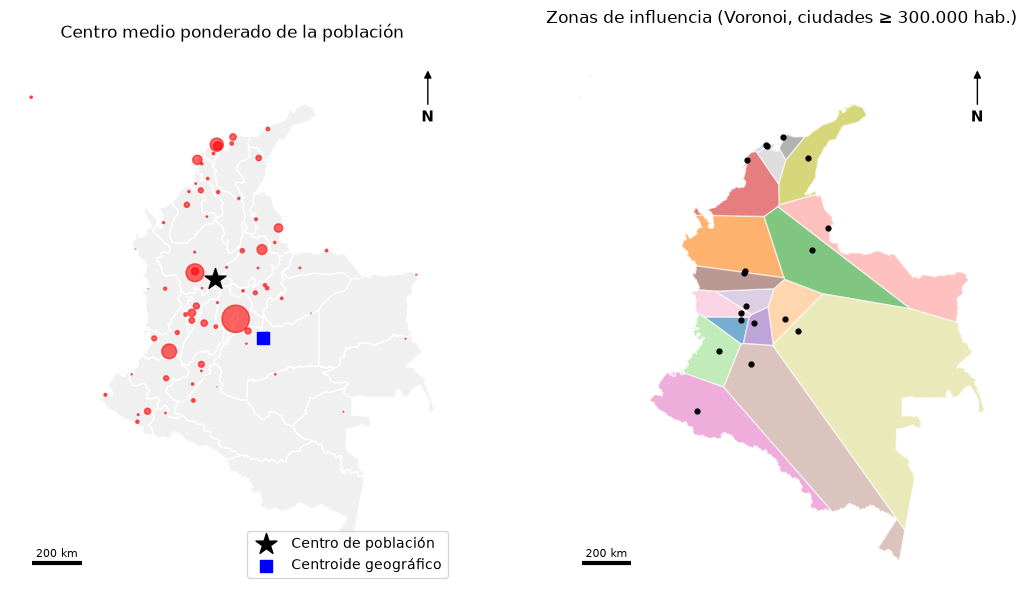

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(13, 7))
deptos.plot(color="#f0f0f0", edgecolor="white", ax=axs[0])
ciudades.plot(ax=axs[0], markersize=ciudades.poblacion / 20000, color="red", alpha=0.6)
gpd.GeoSeries([centro_pob], crs=CRS_METRICO).plot(ax=axs[0], marker="*", color="black", markersize=250, label="Centro de población")
gpd.GeoSeries([centro_geo], crs=CRS_METRICO).plot(ax=axs[0], marker="s", color="blue", markersize=80, label="Centroide geográfico")
axs[0].legend(loc="lower right")
decorar_mapa(axs[0], "Centro medio ponderado de la población", km=200)

voronoi.plot(column="ciudad", cmap="tab20", alpha=0.6, edgecolor="white", ax=axs[1])
grandes.plot(ax=axs[1], color="black", markersize=12)
decorar_mapa(axs[1], "Zonas de influencia (Voronoi, ciudades ≥ 300.000 hab.)", km=200)
for ax in axs:
    ax.set_axis_off()
guardar(fig, "03_distribucion_espacial")
plt.show()

## 10. Operaciones geométricas con Shapely
GeoPandas usa Shapely internamente; aquí se usa directamente para análisis de proximidad alrededor de Bogotá:
`buffer`, `intersection`, `nearest_points`, `Polygon` y predicados espaciales.

In [18]:
bogota = ciudades.loc[ciudades.ciudad.str.contains("Bogot"), "geometry"].iloc[0]
zona = bogota.buffer(150_000)  # radio de 150 km (CRS en metros)

# Porcentaje del área de cada departamento que cae dentro de la zona
deptos["pct_en_zona"] = deptos.geometry.apply(lambda g: g.intersection(zona).area / g.area * 100)
print(deptos[deptos.pct_en_zona > 0].sort_values("pct_en_zona", ascending=False)[["departamento", "pct_en_zona"]].round(1).to_string(index=False))

# Ciudades dentro de la zona y distancia a Bogotá
en_zona = ciudades[ciudades.geometry.within(zona)].copy()
en_zona["dist_km"] = en_zona.geometry.distance(bogota) / 1000
en_zona.sort_values("dist_km")[["ciudad", "poblacion", "dist_km"]].round(1).head(8)

departamento  pct_en_zona
Cundinamarca        100.0
      Bogota        100.0
      Tolima         53.6
      Boyacá         42.1
      Caldas         35.5
        Meta         19.8
    Casanare          4.8
   Santander          3.8
       Huila          3.6
   Risaralda          1.7
     Quindío          1.1
   Antioquia          0.2


,ciudad,poblacion,dist_km
71,Bogota,7772000,0.0
61,Villavicencio,374763,70.1
5,Girardot,130289,86.5
29,Honda,35469,98.5
52,San Martín,16273,109.5
21,Chiquinquirá,53975,116.7
57,Ibagué,421685,128.4
20,Tunja,161412,131.7


In [19]:
# Vecinos de Cundinamarca (predicado `touches`) y punto del río más cercano a Bogotá
cund = deptos.loc[deptos.departamento == "Cundinamarca", "geometry"].iloc[0]
vecinos = deptos[deptos.geometry.touches(cund)].departamento.tolist()
print("Vecinos de Cundinamarca:", vecinos)

rio_cercano = nearest_points(bogota, rios_col.union_all())[1]
print(f"Río más cercano a Bogotá: {bogota.distance(rio_cercano) / 1000:.1f} km")

# Polígono definido a mano (caja de ~100 km) y ciudades que contiene
caja = Polygon([(bogota.x - 5e4, bogota.y - 5e4), (bogota.x + 5e4, bogota.y - 5e4),
                (bogota.x + 5e4, bogota.y + 5e4), (bogota.x - 5e4, bogota.y + 5e4)])
print("Ciudades en la caja:", ciudades[ciudades.geometry.within(caja)].ciudad.tolist())

Vecinos de Cundinamarca: ['Boyacá', 'Huila', 'Caldas', 'Casanare', 'Meta', 'Bogota', 'Tolima']
Río más cercano a Bogotá: 18.3 km
Ciudades en la caja: ['Villavicencio', 'Bogota']


## 11. Datos ráster con Rasterio
Se integra el ráster de relieve con los vectores:
1. Metadatos y recorte al territorio colombiano.
2. Estadística zonal por departamento (ráster → atributo vectorial).
3. Ráster → vector (`features.shapes`) y vector → ráster (`features.rasterize`).

In [20]:
ruta_tif = next(d_relieve.glob("*.tif"))
with rasterio.open(ruta_tif) as src:
    print("CRS:", src.crs, "| Tamaño:", src.width, "x", src.height, "| Bandas:", src.count, "| Tipo:", src.dtypes[0])
    print("Resolución (°):", src.res, "| Límites:", src.bounds)

    # Recorte con la geometría de Colombia (el ráster está en EPSG:4326)
    col_4326 = deptos.to_crs(src.crs)
    recorte, transf = mask(src, col_4326.geometry, crop=True, nodata=0)
    crs_ras = src.crs

# Una sola banda en escala de grises: 0 (sombra) a 255 (iluminado); 0 también es el valor fuera de Colombia
gris = recorte[0].astype(float)
print("Recorte:", recorte.shape)

CRS: EPSG:4326 | Tamaño: 10800 x 5400 | Bandas: 1 | Tipo: uint8
Resolución (°): (0.03333333333333, 0.03333333333333) | Límites: BoundingBox(left=-179.99999999999997, bottom=-89.99999999998201, right=179.99999999996405, top=90.0)
Recorte: (1, 536, 446)


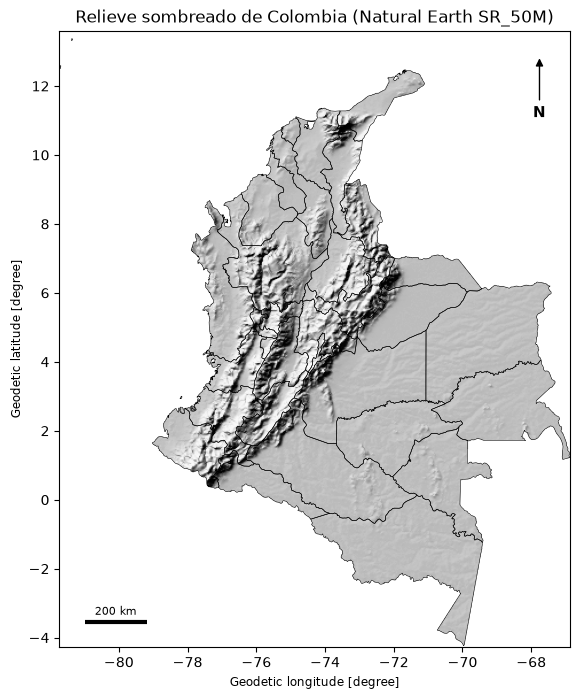

In [21]:
def mostrar_relieve(ax):
    """Dibuja el relieve en grises, ocultando lo que queda fuera de Colombia."""
    ax.imshow(np.ma.masked_equal(gris, 0), cmap="gray", extent=plotting_extent(recorte[0], transf))

fig, ax = plt.subplots(figsize=(7, 8))
mostrar_relieve(ax)
col_4326.boundary.plot(ax=ax, color="black", linewidth=0.4)
decorar_mapa(ax, "Relieve sombreado de Colombia (Natural Earth SR_50M)", km=200, grados=True)
guardar(fig, "04_relieve")
plt.show()

In [22]:
# Estadística zonal: brillo medio y variabilidad del relieve por departamento
# Se rasteriza cada departamento con el mismo grid del recorte y se agregan los píxeles.
ids = np.arange(1, len(col_4326) + 1)
etiquetas = features.rasterize(zip(col_4326.geometry, ids), out_shape=gris.shape, transform=transf, fill=0, dtype="int32")

deptos["relieve_medio"] = [gris[etiquetas == i].mean() if (etiquetas == i).any() else np.nan for i in ids]
deptos["relieve_std"] = [gris[etiquetas == i].std() if (etiquetas == i).any() else np.nan for i in ids]

# Un std alto indica mayor contraste de sombras, es decir, relieve más accidentado
deptos.nlargest(5, "relieve_std")[["departamento", "relieve_medio", "relieve_std"]].round(1)

,departamento,relieve_medio,relieve_std
32,Risaralda,184.6,58.7
10,Boyacá,175.2,58.2
29,Tolima,161.4,58.0
22,Huila,180.6,56.8
24,Caldas,184.9,53.9


In [23]:
# Ráster -> vector: zonas de relieve accidentado (std local alto) convertidas a polígonos
std_local = generic_filter(gris, np.std, size=5)
accidentado = ((std_local > np.nanpercentile(std_local[gris > 0], 85)) & (gris > 0)).astype("uint8")

formas = features.shapes(accidentado, mask=accidentado == 1, transform=transf)
zonas = gpd.GeoDataFrame(geometry=[shape(g) for g, _ in formas], crs=crs_ras)
zonas = zonas.to_crs(CRS_METRICO)
zonas["area_km2"] = zonas.area / 1e6
print(f"{len(zonas)} polígonos de relieve accidentado | área total: {zonas.area_km2.sum():,.0f} km²")

72 polígonos de relieve accidentado | área total: 170,240 km²


## 12. Elevación real: picos de Natural Earth
Natural Earth no ofrece un modelo de elevación, pero sí puntos de elevación en metros. Se usan para dos cosas:
1. Responder el reto del enunciado: *¿dónde hay elevaciones por encima de un umbral?* (aquí 4.000 m).
2. **Validar el indicador de relieve** del ráster: si `std_local` (variabilidad del sombreado) mide montaña, debe ser mayor en los picos que en las llanuras.

In [24]:
picos = gpd.read_file(d_picos).to_crs(CRS_METRICO)
picos = picos[picos.within(deptos.union_all())].copy()
picos["pico"] = picos["name"].fillna(picos["comment"])  # un punto solo trae el nombre en `comment`
picos = (gpd.sjoin(picos[["pico", "elevation", "geometry"]], deptos[["departamento", "geometry"]], predicate="within")
         .drop(columns="index_right"))

altos = picos[picos.elevation >= 4000]
print(f"{len(picos)} puntos de elevación en Colombia, {len(altos)} sobre 4.000 m")
picos.sort_values("elevation", ascending=False)[["pico", "elevation", "departamento"]]

7 puntos de elevación en Colombia, 4 sobre 4.000 m


,pico,elevation,departamento
485,Pico Cristóbal Colón,5775.0,Magdalena
692,Ritacuba Blanco,5410.0,Boyacá
493,Nevado del Ruiz,5311.0,Tolima
683,Volcán Galeras,4276.0,Nariño
691,Sierra de Macarena High Point,2615.0,Meta
704,Alto de Buey,1810.0,Chocó
699,Cerro Maine Hanari,860.0,Amazonas


In [25]:
# Validación del relieve: variabilidad local del ráster en los picos vs. puntos aleatorios en llanuras
def valor_en(puntos, matriz):
    p = puntos.to_crs(crs_ras)
    filas, cols = rowcol(transf, p.x.values, p.y.values)
    return matriz[np.array(filas), np.array(cols)]

llanura = deptos[deptos.departamento.isin(["Vichada", "Guainía", "Vaupés", "Amazonas", "Guaviare"])]
muestra = (gpd.GeoSeries([llanura.union_all()], crs=CRS_METRICO)
           .sample_points(200, rng=0).explode(index_parts=False))

en_picos = valor_en(picos.geometry, std_local)
en_llanura = valor_en(muestra, std_local)
print(f"Variabilidad local mediana en picos: {np.median(en_picos):.1f} | en llanuras: {np.median(en_llanura):.1f}")
print(f"Picos con variabilidad mayor que la mediana de las llanuras: {(en_picos > np.median(en_llanura)).sum()} de {len(picos)}")

Variabilidad local mediana en picos: 37.5 | en llanuras: 2.9
Picos con variabilidad mayor que la mediana de las llanuras: 7 de 7


In [26]:
# Distancia de las ciudades principales al pico de más de 4.000 m más cercano
ciudades["dist_pico_km"] = ciudades.geometry.distance(altos.union_all()) / 1000
ciudades.nlargest(5, "poblacion")[["ciudad", "poblacion", "dist_pico_km"]].round(0)

,ciudad,poblacion,dist_pico_km
71,Bogota,7772000,141.0
69,Medellín,3297000,155.0
70,Cali,2254000,211.0
65,Barranquilla,1798000,122.0
56,Bucaramanga,1009000,116.0


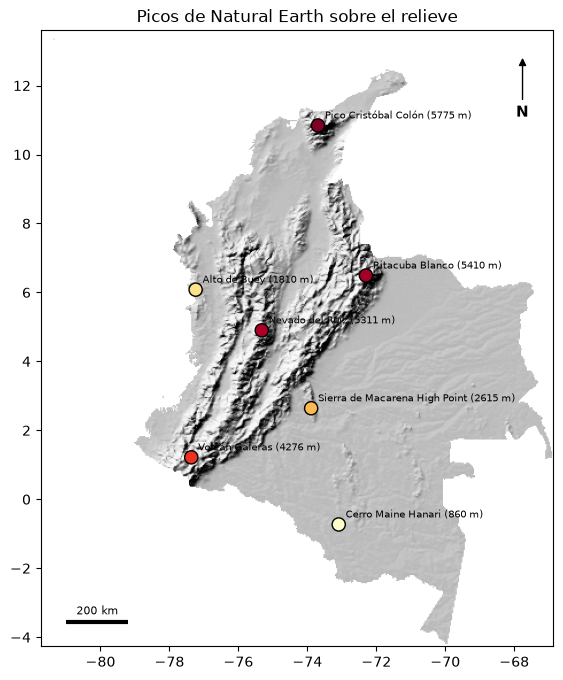

In [27]:
fig, ax = plt.subplots(figsize=(7, 8))
mostrar_relieve(ax)
p4326 = picos.to_crs(crs_ras)
ax.scatter(p4326.geometry.x, p4326.geometry.y, c=p4326.elevation, cmap="YlOrRd", edgecolor="black", s=90, zorder=3)
for _, r in p4326.iterrows():
    ax.annotate(f"{r.pico} ({r.elevation:.0f} m)", (r.geometry.x, r.geometry.y), xytext=(5, 5), textcoords="offset points", fontsize=7)
decorar_mapa(ax, "Picos de Natural Earth sobre el relieve", km=200, grados=True)
guardar(fig, "05_picos")
plt.show()

## 13. Mapa final y conclusiones

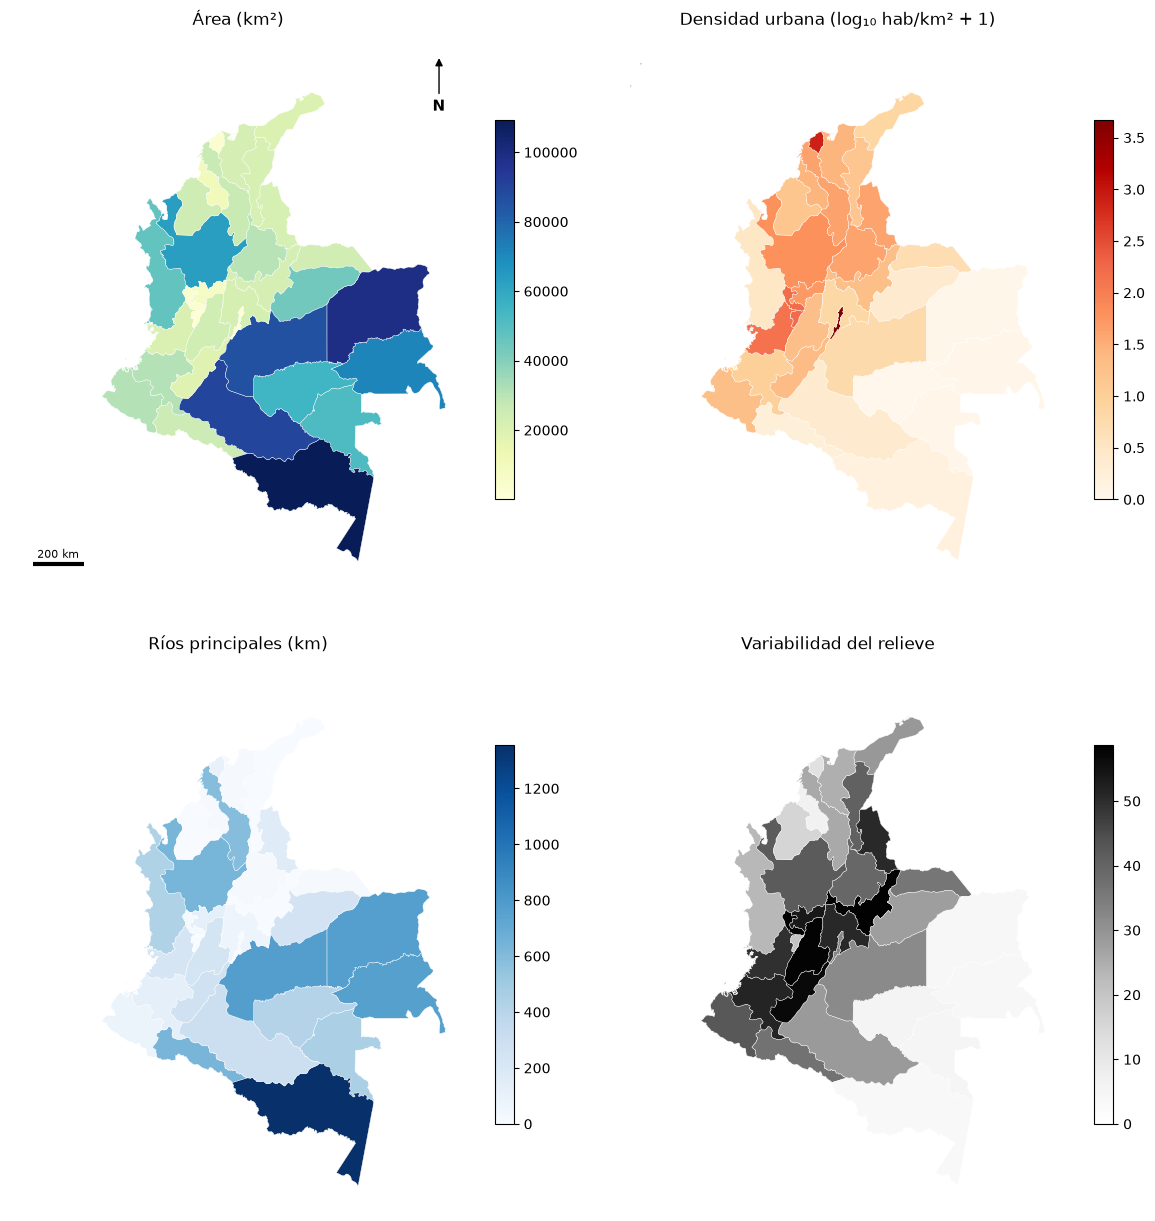

In [28]:
# Panel comparativo de los indicadores por departamento (la densidad va en escala logarítmica por el peso de Bogotá)
variables = [("area_km2", "Área (km²)", "YlGnBu"),
             ("densidad_urbana", "Densidad urbana (log₁₀ hab/km² + 1)", "OrRd"),
             ("km_rios", "Ríos principales (km)", "Blues"),
             ("relieve_std", "Variabilidad del relieve", "Greys")]
fig, axs = plt.subplots(2, 2, figsize=(12, 13))
for ax, (col, titulo, cmap) in zip(axs.flat, variables):
    valor = np.log10(deptos[col] + 1) if col == "densidad_urbana" else deptos[col]
    deptos.assign(valor=valor).plot(column="valor", cmap=cmap, legend=True, edgecolor="white", linewidth=0.3,
                                    ax=ax, legend_kwds={"shrink": 0.6})
    decorar_mapa(ax, titulo, km=200 if col == "area_km2" else None, norte=col == "area_km2")
    ax.set_axis_off()
plt.tight_layout()
guardar(fig, "07_panel_indicadores")
plt.show()

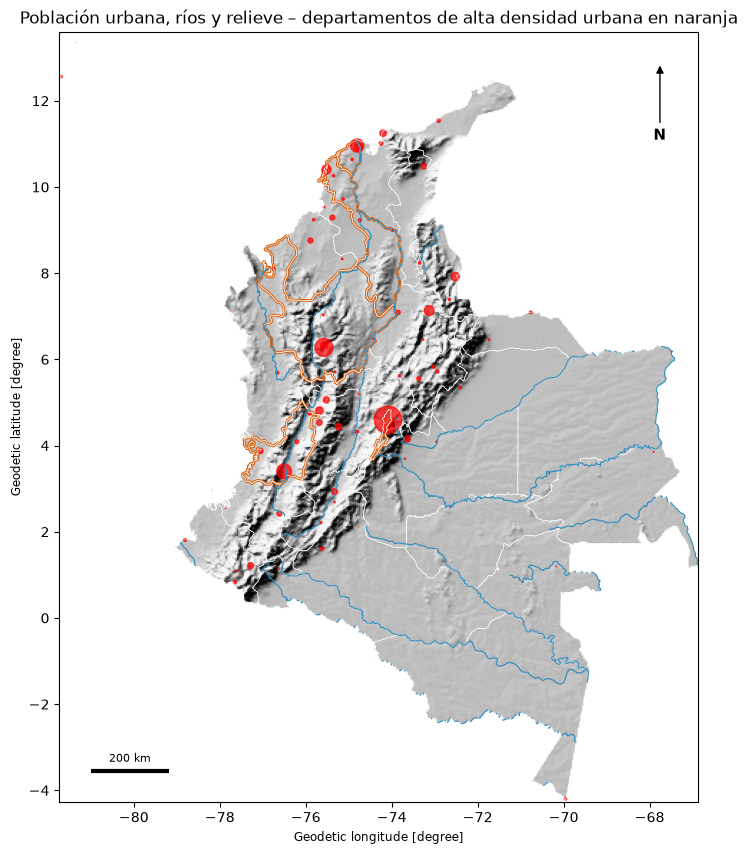

In [29]:
fig, ax = plt.subplots(figsize=(9, 10))
mostrar_relieve(ax)
deptos.to_crs(crs_ras).boundary.plot(ax=ax, color="white", linewidth=0.4)
reto.to_crs(crs_ras).plot(ax=ax, facecolor="none", edgecolor="#d95f0e", linewidth=2)
rios_col.to_crs(crs_ras).plot(ax=ax, color="#2b8cbe", linewidth=0.8)
ciudades.to_crs(crs_ras).plot(ax=ax, markersize=ciudades.poblacion / 20000, color="red", alpha=0.7)
decorar_mapa(ax, "Población urbana, ríos y relieve – departamentos de alta densidad urbana en naranja", km=200, grados=True)
guardar(fig, "06_mapa_final")
plt.show()

In [30]:
deptos[["departamento", "area_km2", "pob_urbana", "densidad_urbana", "km_rios", "relieve_std"]].corr(numeric_only=True).round(2)

,area_km2,pob_urbana,densidad_urbana,km_rios,relieve_std
area_km2,1.00,-0.23,-0.31,0.82,-0.37
pob_urbana,-0.23,1.00,0.80,-0.12,0.15
densidad_urbana,-0.31,0.80,1.00,-0.22,-0.09
km_rios,0.82,-0.12,-0.22,1.00,-0.37
relieve_std,-0.37,0.15,-0.09,-0.37,1.00


**Interpretación**
- Cinco departamentos superan el umbral del reto (P75 ≈ 41,6 hab/km²): Bogotá D.C. (≈ 4.660 hab/km²), Atlántico (≈ 770), Valle del Cauca, Antioquia y Bolívar. Reúnen las principales ciudades del país, en las regiones Andina y Caribe. Bogotá y Atlántico son robustos: siguen en el reto con el percentil 90; Bolívar está en el borde del umbral y Santander solo entra con el percentil 60.
- El centro medio de la población urbana queda ≈ 307 km al noroeste del centroide geográfico del país: la población se inclina hacia los Andes y el Caribe.
- Hay una primacía urbana marcada: Bogotá concentra el 29,2 % de la población urbana registrada, las 3 mayores ciudades el 50,1 % y las 5 mayores el 60,7 %.
- El 59,8 % de esa población vive en ciudades a ≤ 25 km de un río principal (34 de 72 ciudades), aunque la capa solo incluye los ríos principales.
- La zona de influencia más extensa es la de Villavicencio (≈ 367.000 km²), que cubre la Orinoquía y gran parte de la Amazonía, donde casi no hay ciudades grandes.
- Cuatro picos superan los 4.000 m: Cristóbal Colón (5.775 m, Magdalena), Ritacuba Blanco (5.410 m, Boyacá), Nevado del Ruiz (5.311 m, Tolima) y Galeras (4.276 m, Nariño). Ninguna de las cinco mayores ciudades está a menos de 100 km de uno de ellos.
- El indicador de relieve del ráster se valida con los picos: su variabilidad local mediana es 37,5 frente a 2,9 en las llanuras, y los 7 picos superan esa mediana. La muestra es pequeña (7 puntos), pero respalda el uso de `relieve_std` como indicador de montaña.
- Los departamentos con más kilómetros de río (Amazonas, Meta, Vichada, Guainía) son extensos y tienen muy poca población urbana: la correlación entre densidad urbana y km de río es débil y negativa (≈ -0,22).
- El relieve más accidentado (mayor `relieve_std`) aparece en departamentos andinos como Risaralda, Boyacá, Tolima, Huila y Caldas. Su correlación con la densidad urbana es débil (≈ -0,09), por lo que el relieve por sí solo no explica dónde se concentra la población.
- Limitaciones: las ciudades de Natural Earth son una muestra y no un censo; el ráster es un relieve sombreado y no un DEM, así que `relieve_std` es un indicador relativo y no una altitud.

---
## 14. Parte 2 – Integración de una segunda biblioteca *(a cargo de mi compañero)*

Variables disponibles de la parte 1:

| Variable | Contenido |
|---|---|
| `deptos` | GeoDataFrame de departamentos (EPSG:9377) con área, población urbana, densidad, km de ríos, relieve y bandera `reto` |
| `reto` | Subconjunto de `deptos` que cumple la condición del reto |
| `ciudades` | Ciudades con población (EPSG:9377) |
| `rios_col` | Ríos recortados a Colombia (EPSG:9377) |
| `recorte`, `transf` | Ráster de relieve recortado y su transformación afín (EPSG:4326) |

In [31]:
# Parte 2: tu código aquí

## 15. Evaluación de las herramientas y dificultades
*(Pendiente: utilidad de las herramientas y dificultades encontradas.)*